# Performing DEG Pathway analysis (limma, R) on Pseudobulked DC2 data from atlas
* Ovarian cancer samples only
* dataframes made previously (2026-09-29_OC_cDC2subset_PseudobulkingSampleType.jpynb), separate for each DC2 subset and each has seperate metadata file
* Following code from ChatGPT -15/5/26 and used previously in /scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/R_Jupyter_Analysis/2026-05-15_OC_Pseudobulk_PrimaryvMets_DEG_Visualisation.ipynb
* Use the R environment (R_env)

In [2]:
library(limma)
library(edgeR)
library(dplyr)
library(RColorBrewer)
library(Seurat)

In [3]:
library(msigdbr)

In [4]:
library(GSEABase)

Loading required package: BiocGenerics


Attaching package: ‘BiocGenerics’


The following object is masked from ‘package:SeuratObject’:

    intersect


The following objects are masked from ‘package:dplyr’:

    combine, intersect, setdiff, union


The following object is masked from ‘package:limma’:

    plotMA


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, intersect, is.unsorted, lapply, Map, mapply,
    match, mget, order, paste, pmax, pmax.int, pmin, pmin.int,
    Position, rank, rbind, Reduce, rownames, sapply, saveRDS, setdiff,
    table, tapply, union, unique, unsplit, which.max, which.min


Loading required package: Biobase

Welcome to Bioconductor

    Vignettes contain introductory material; view with
    'browseVignettes(

In [5]:
setwd("/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code")

## Read in Pseudobulked DC2 data from 2026-09-29_OC_cDC2subset_PseudobulkingSampleType.ipynb

In [6]:
getwd()

[1] "/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code"

In [21]:
#read in csv files for pseudobulked data
#read only the 5 DC2 subsets with more than 20 cells per condition(primary vs metastatic)

pseudobulk_IL18 <- read.csv("NewDC2subsets_Analysis/DC2_Pseudobulk/pseudobulk_IL18_data.csv")
pseudobulk_ISG <- read.csv("NewDC2subsets_Analysis/DC2_Pseudobulk/pseudobulk_ISG_data.csv")
pseudobulk_SIK3 <- read.csv("NewDC2subsets_Analysis/DC2_Pseudobulk/pseudobulk_SIK3_data.csv")
pseudobulk_dc2 <- read.csv("NewDC2subsets_Analysis/DC2_Pseudobulk/pseudobulk_dc2_data.csv")
pseudobulk_dc3 <- read.csv("NewDC2subsets_Analysis/DC2_Pseudobulk/pseudobulk_dc3_data.csv")



In [22]:
#read in csv files for metadata

IL18_metadata <- read.csv("NewDC2subsets_Analysis/DC2_Pseudobulk/pseudobulk_metadata_IL18.csv")
ISG_metadata <- read.csv("NewDC2subsets_Analysis/DC2_Pseudobulk/pseudobulk_metadata_ISG.csv")
SIK3_metadata <- read.csv("NewDC2subsets_Analysis/DC2_Pseudobulk/pseudobulk_metadata_SIK3.csv")
dc2_metadata <- read.csv("NewDC2subsets_Analysis/DC2_Pseudobulk/pseudobulk_metadata_dc2.csv")
dc3_metadata <- read.csv("NewDC2subsets_Analysis/DC2_Pseudobulk/pseudobulk_metadata_dc3.csv")

## Start with IL18 DC2s

In [9]:
class(pseudobulk_IL18)

[1] "data.frame"

In [10]:
head(pseudobulk_IL18)

,X,GSE180661_SPECTRUM.OV.003_S1_UNSORTED_LEFT_UPPER_QUADRANT,GSE180661_SPECTRUM.OV.009_S1_CD45P_BOWEL,GSE180661_SPECTRUM.OV.009_S1_CD45P_INFRACOLIC_OMENTUM,GSE180661_SPECTRUM.OV.009_S1_CD45P_PELVIC_PERITONEUM,GSE180661_SPECTRUM.OV.009_S1_CD45P_RIGHT_UPPER_QUADRANT,GSE180661_SPECTRUM.OV.014_S1_CD45P_BOWEL,GSE180661_SPECTRUM.OV.014_S1_CD45P_LEFT_OVARY,GSE180661_SPECTRUM.OV.014_S1_CD45P_PELVIC_PERITONEUM,GSE180661_SPECTRUM.OV.022_S1_CD45P_ASCITES,⋯,GSE180661_SPECTRUM.OV.115_S1_CD45P_PELVIC_PERITONEUM,GSE180661_SPECTRUM.OV.115_S1_CD45P_RIGHT_ADNEXA,GSE180661_SPECTRUM.OV.118_S1_CD45P_LEFT_ADNEXA,GSE180661_SPECTRUM.OV.118_S1_CD45P_PELVIC_PERITONEUM,GSE180661_SPECTRUM.OV.118_S1_CD45P_RIGHT_ADNEXA,GSE184880_HGSOC_Cancer1,GSE184880_HGSOC_Cancer7,GSE184880_Healthy_Norm3,GSE213243_HGSOC_ascites,GSE217517_HGSOC_pt2
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,KLHL17,-0.1125081,-0.2831936,-0.1437022,-0.2761633,7.4777655,11.6354090,5.483738,-1.040186,-0.1355669,⋯,-0.5079945,-0.4831628,9.6768074,-0.2146680,-0.4901653,-0.3126361,-0.31047127,-0.1898368,-0.3319154,-0.1551964
2,HES4,-0.2649864,-1.7007686,-0.9779288,-1.4995446,-0.8168666,-9.1542802,-4.247257,-1.126514,-0.4688702,⋯,-2.1378174,-1.6836270,-1.4399777,-0.5462781,-1.9668876,-0.2312666,0.03742275,-0.5773711,-0.6272758,-0.4512505
3,ISG15,0.7779065,4.3788717,4.5730731,7.4045567,3.4370723,7.7360643,-1.695497,3.204520,2.6137026,⋯,-1.4717386,-1.0901660,0.9132879,1.9775658,0.2950509,-0.3338319,0.08980434,0.5850886,-1.1495952,0.9129194
4,AGRN,-0.1790436,3.0553820,-0.4977805,-0.7267220,-0.3813677,0.7035992,-2.514355,5.403947,-0.2981938,⋯,-1.0847126,1.5656882,-0.8990469,-0.3716557,-1.1354640,-0.3029635,-0.37974578,-0.3063883,-0.4688194,1.7637798
5,TNFRSF18,-0.2460078,-0.9739197,-0.7052251,-0.9935963,-0.5202888,-5.9837349,-2.579263,-2.135563,-0.4768122,⋯,-1.2353086,-1.1955583,-1.1358223,-0.4664193,-1.3492457,-0.2465032,-0.20647621,-0.2628269,-0.5039502,-0.5389408
6,TNFRSF4,-0.2486940,-1.0737704,-0.7405825,-1.0763419,-0.5762799,-5.1412880,-2.964110,-2.342563,-0.4808185,⋯,-1.3428428,-1.2590829,-1.1463666,-0.4674854,-1.3998288,-0.2074768,-0.10233145,-0.2893519,-0.4830124,-0.6751487


In [11]:
head(IL18_metadata)

,integration_id,sample_type_major2
,<chr>,<chr>
1,GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_UPPER_QUADRANT,metastatic tumour
2,GSE180661_SPECTRUM-OV-009_S1_CD45P_BOWEL,metastatic tumour
3,GSE180661_SPECTRUM-OV-009_S1_CD45P_INFRACOLIC_OMENTUM,metastatic tumour
4,GSE180661_SPECTRUM-OV-009_S1_CD45P_PELVIC_PERITONEUM,metastatic tumour
5,GSE180661_SPECTRUM-OV-009_S1_CD45P_RIGHT_UPPER_QUADRANT,metastatic tumour
6,GSE180661_SPECTRUM-OV-014_S1_CD45P_BOWEL,metastatic tumour


### Align the metadata and pseudobulk data by sample


In [23]:
length(colnames(pseudobulk_IL18))
length(IL18_metadata$integration_id)

[1] 69

[1] 68

In [24]:
stopifnot(all(colnames(pseudobulk_IL18) %in% IL18_metadata$integration_id))

IL18_metadata <- IL18_metadata[
    match(colnames(pseudobulk_IL18), IL18_metadata$integration_id),
    , drop = FALSE
]

rownames(IL18_metadata) <- IL18_metadata$integration_id

ERROR: Error: all(colnames(pseudobulk_IL18) %in% IL18_metadata$integration_id) is not TRUE


In [12]:
all(colnames(pseudobulk_IL18) == IL18_metadata$integration_id)

Warning message in colnames(pseudobulk_IL18) == IL18_metadata$integration_id:
“longer object length is not a multiple of shorter object length”


[1] FALSE

In [13]:
IL18_metadata <- IL18_metadata[
  match(colnames(pseudobulk_IL18),
        IL18_metadata$integration_id),
]

### Align the metadata and pseudobulk information by sample (integration id)

In [25]:
## 1. Move the unnamed first column (gene IDs) to row names
gene_ids <- pseudobulk_IL18[[1]]

counts_mat <- as.matrix(pseudobulk_IL18[, -1, drop = FALSE])
rownames(counts_mat) <- gene_ids

## Optional: ensure counts are numeric
storage.mode(counts_mat) <- "numeric"

## 2. Set metadata row names to integration_id
rownames(IL18_metadata) <- IL18_metadata$integration_id

## 3. Keep only samples present in both objects
common_samples <- intersect(
    colnames(counts_mat),
    rownames(IL18_metadata)
)

counts_mat <- counts_mat[, common_samples, drop = FALSE]
IL18_metadata <- IL18_metadata[common_samples, , drop = FALSE]

## 4. Reorder metadata rows to exactly match count-matrix columns
IL18_metadata <- IL18_metadata[
    match(colnames(counts_mat), rownames(IL18_metadata)),
    , drop = FALSE
]

## 5. Verify alignment
stopifnot(identical(colnames(counts_mat), rownames(IL18_metadata)))

### Keep only Primary and Metastatic

In [14]:
IL18_metadata <- IL18_metadata %>%
  filter(sample_type_major2 %in%
         c("primary tumour",
           "metastatic tumour"))

pseudobulk_IL18 <- pseudobulk_IL18[
    ,
    IL18_metadata$integration_id
]

In [26]:
head(IL18_metadata)

,integration_id,sample_type_major2
,<chr>,<chr>
GSE184880_HGSOC_Cancer1,GSE184880_HGSOC_Cancer1,primary tumour
GSE184880_HGSOC_Cancer7,GSE184880_HGSOC_Cancer7,primary tumour
GSE184880_Healthy_Norm3,GSE184880_Healthy_Norm3,healthy
GSE213243_HGSOC_ascites,GSE213243_HGSOC_ascites,ascites
GSE217517_HGSOC_pt2,GSE217517_HGSOC_pt2,primary tumour


In [16]:
#Convert condition to factor and make primary tumour the reference
IL18_metadata$sample_type_major2 <- factor(
    IL18_metadata$sample_type_major2,
    levels = c(
        "primary tumour",
        "metastatic tumour"
    )
)

### Create a reusable limma pseudobulk function

In [17]:
run_limma_deg <- function(counts, metadata){

    dge <- DGEList(counts = counts)

    # Filter lowly expressed genes
    keep <- filterByExpr(
        dge,
        group = metadata$sample_type_major2
    )

    dge <- dge[keep, , keep.lib.sizes = FALSE]

    # Normalisation
    dge <- calcNormFactors(dge)

    # Design matrix
    design <- model.matrix(
        ~ sample_type_major2,
        data = metadata
    )

    # Voom transformation
    v <- voom(
        dge,
        design,
        plot = TRUE
    )

    # Fit model
    fit <- lmFit(v, design)

    fit <- eBayes(fit)

    results <- topTable(
        fit,
        coef = 2,
        number = Inf
    )

    return(results)
}

## New run_limma_deg function from Perplexity - 16/10/26

In [18]:
run_limma_deg <- function(counts, metadata) {

    counts <- as.matrix(counts)

    ## Ensure samples in counts and metadata match
    if (!identical(colnames(counts), rownames(metadata))) {
        common <- intersect(colnames(counts), rownames(metadata))
        if (length(common) < 2) {
            stop("Fewer than two shared samples between colnames(counts) and rownames(metadata).")
        }
        counts <- counts[, common, drop = FALSE]
        metadata <- metadata[common, , drop = FALSE]
    }

    ## Identify invalid gene rows: NA, Inf, -Inf, or negative counts
    bad_rows <- rowSums(
        is.na(counts) |
        !is.finite(counts) |
        counts < 0
    ) > 0

    if (any(bad_rows)) {
        warning(sprintf(
            "Removing %d gene(s) with NA, non-finite, or negative counts.",
            sum(bad_rows)
        ))
        counts <- counts[!bad_rows, , drop = FALSE]
    }

    ## Remove all-zero genes as an additional safeguard
    zero_rows <- rowSums(counts) == 0
    if (any(zero_rows)) {
        counts <- counts[!zero_rows, , drop = FALSE]
    }

    if (nrow(counts) == 0) {
        stop("No valid genes remain after removing invalid or zero-count rows.")
    }

    dge <- DGEList(counts = counts)

    # Filter lowly expressed genes
    keep <- filterByExpr(
        dge,
        group = metadata$sample_type_major2
    )

    dge <- dge[keep, , keep.lib.sizes = FALSE]

    # Normalisation
    dge <- calcNormFactors(dge)

    # Design matrix
    design <- model.matrix(
        ~ sample_type_major2,
        data = metadata
    )

    # Voom transformation
    v <- voom(
        dge,
        design,
        plot = TRUE
    )

    # Fit model
    fit <- lmFit(v, design)
    fit <- eBayes(fit)

    results <- topTable(
        fit,
        coef = 2,
        number = Inf
    )

    return(results)
}

### Run DEG for each cell type

In [19]:
deg_il18 <- run_limma_deg(
    pseudobulk_IL18,
    IL18_metadata
)


ERROR: Error in run_limma_deg(pseudobulk_IL18, IL18_metadata): Fewer than two shared samples between colnames(counts) and rownames(metadata).


In [ ]:

deg_isg <- run_limma_deg(
    pseudobulk_ISG,
    ISG_metadata
)

deg_sik3 <- run_limma_deg(
    pseudobulk_SIK3,
    SIK3_metadata 
)

deg_dc2 <- run_limma_deg(
    pseudobulk_dc2,
    dc2_metadata 
)

deg_dc3 <- run_limma_deg(
    pseudobulk_dc3,
    dc3_metadata 
)

In [ ]:
#write.csv(deg_dc1, "Pseudobulk/dc1_limma_DEG.csv")
#write.csv(deg_dc2, "Pseudobulk/dc2_limma_DEG.csv")
#write.csv(deg_mregDC, "Pseudobulk/mregdc_limma_DEG.csv")

### Select top DEGs

In [ ]:
#choose top genes by adjusted p value
top20_dc1 <- rownames(
    deg_dc1 %>%
        arrange(adj.P.Val) %>%
        head(20)
)


top20_dc2 <- rownames(
    deg_dc2 %>%
        arrange(adj.P.Val) %>%
        head(20)
)


top20_mregdc <- rownames(
    deg_mregDC %>%
        arrange(adj.P.Val) %>%
        head(20)
)

### Create heatmap of top DEGs

In [ ]:
run_limma_deg <- function(counts, metadata){

    dge <- DGEList(counts = counts)

    keep <- filterByExpr(
        dge,
        group = metadata$sample_type_major2
    )

    dge <- dge[keep, ,
               keep.lib.sizes = FALSE]

    dge <- calcNormFactors(dge)

    design <- model.matrix(
        ~ sample_type_major2,
        data = metadata
    )

    v <- voom(dge, design)

    fit <- lmFit(v, design)
    fit <- eBayes(fit)

    results <- topTable(
        fit,
        coef = 2,
        number = Inf
    )

    return(list(
        deg = results,
        voom = v
    ))
}

In [ ]:
res1 <- run_limma_deg(
    pseudobulk_DC1,
    metadata_DC1
)

deg1 <- res1$deg
v1 <- res1$voom

Setting first column of `counts` as gene annotation.



In [ ]:
library(pheatmap)
library(ggplot2)
library(ggrepel)

## DC1

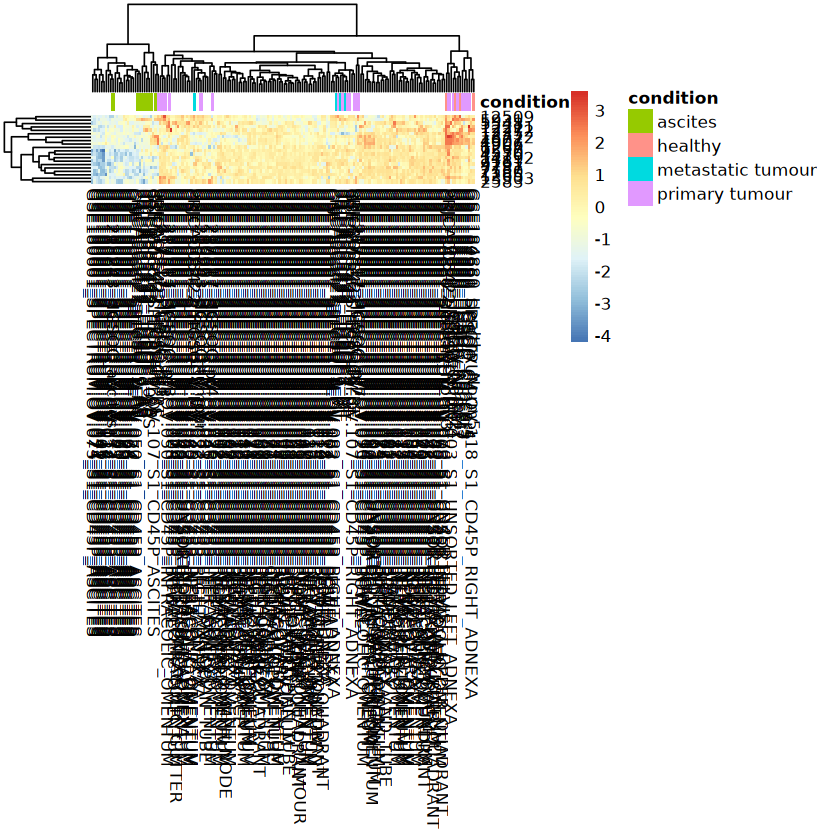

In [ ]:
top20_dc1 <- rownames(
    deg1 %>%
        arrange(adj.P.Val) %>%
        head(20)
)

mat <- v1$E[top20_dc1, ]

mat_scaled <- t(scale(t(mat)))

annotation_col <- data.frame(
    condition =
        metadata_DC1$sample_type_major2
)

rownames(annotation_col) <-
    metadata_DC1$integration_id

pheatmap(
    mat_scaled,
    annotation_col =
        annotation_col,
    cluster_cols = TRUE,
    show_rownames = TRUE
)

options(repr.plot.width=12, repr.plot.height=12)

In [ ]:
head(deg1)

,X,logFC,AveExpr,t,P.Value,adj.P.Val,B
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
14192,FOSB,6.565858,7.386986,10.529104,1.628783e-20,6.204036e-17,35.66422
2150,CXCR4,5.089592,7.537479,8.102755,7.845667e-14,1.494207e-10,20.91339
9530,NR4A1,4.595603,7.126646,7.706649,8.320311e-13,1.056402e-09,18.64361
1265,RGS1,5.125234,8.074601,7.484649,3.049695e-12,2.518460e-09,17.40451
12509,COL1A1,5.228293,3.081121,7.470755,3.305934e-12,2.518460e-09,17.07444
9291,SLC2A3,5.011004,6.708745,7.338134,7.113677e-12,4.515999e-09,16.57676


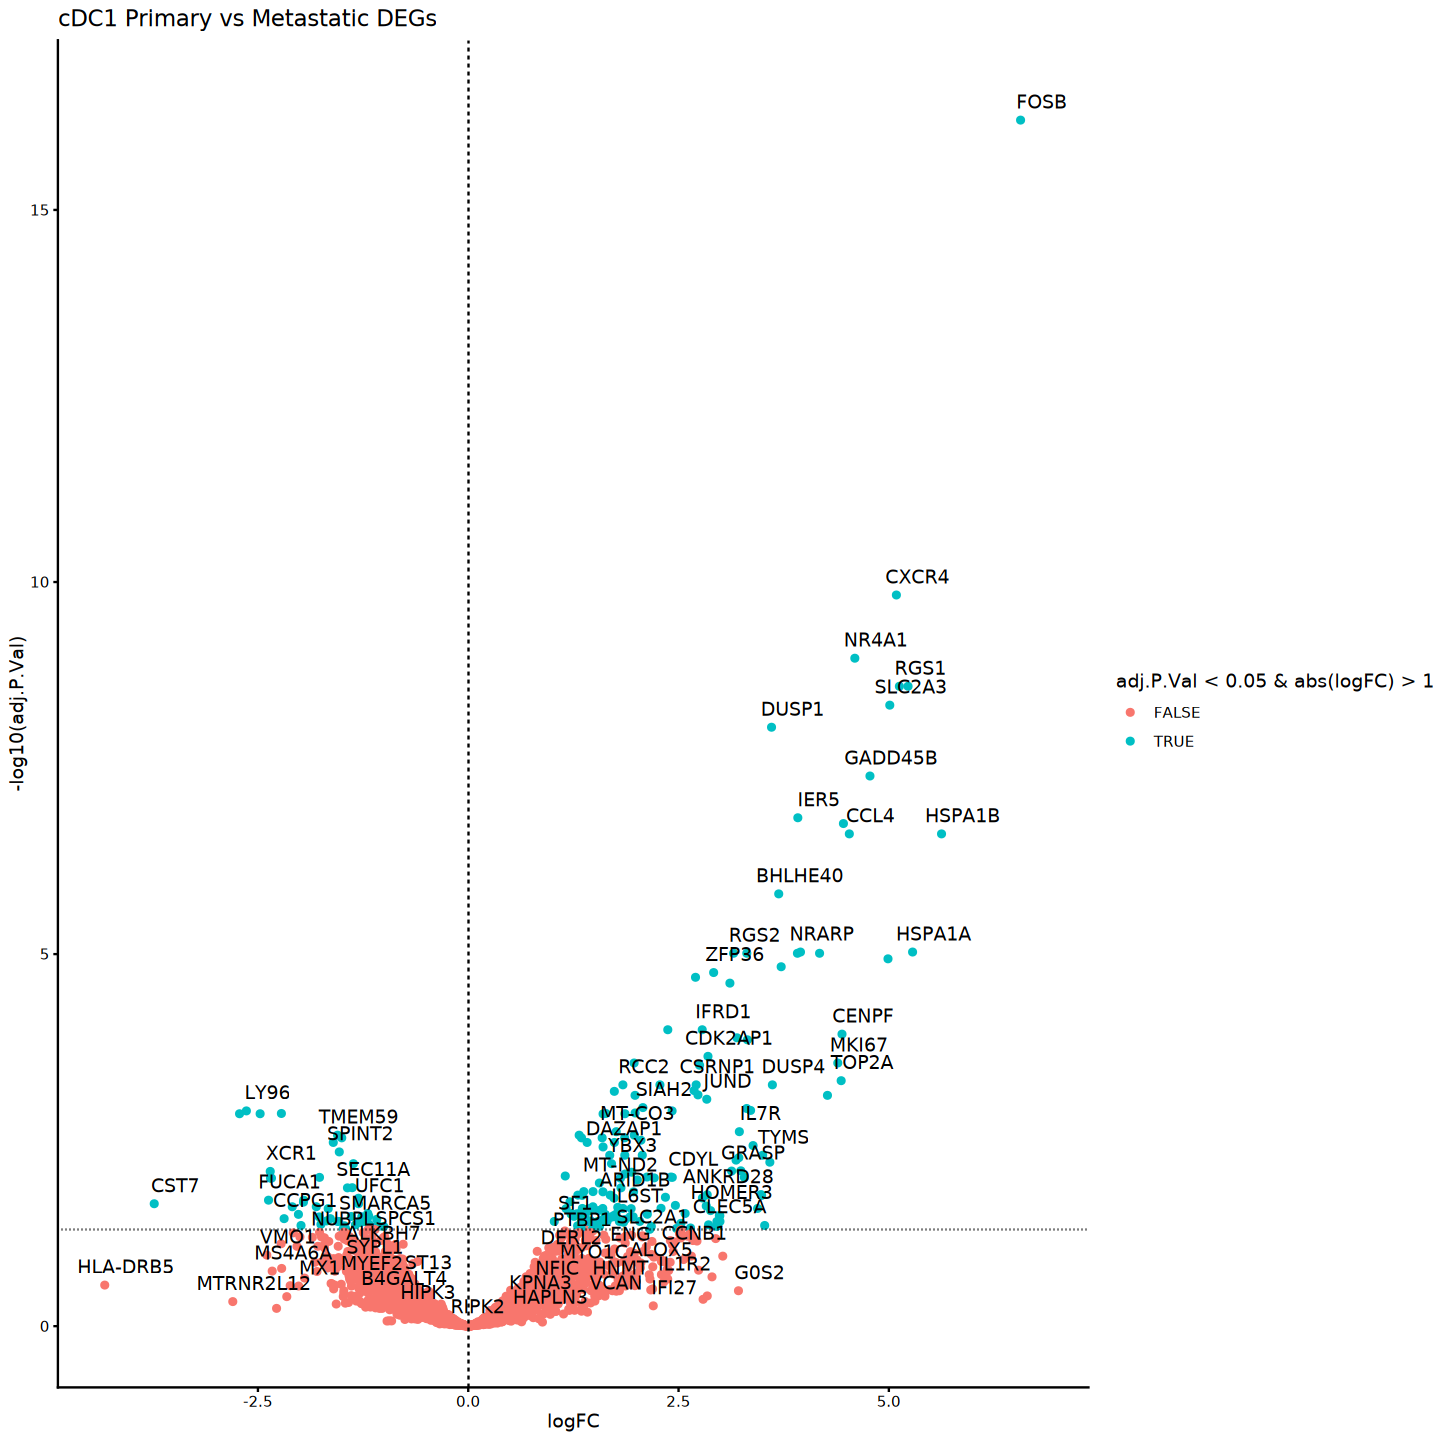

In [ ]:
deg1$gene <- rownames(deg1)

ggplot(deg1,
       aes(logFC, -log10(adj.P.Val), label = X)) +
       geom_point(aes(
        color =
        adj.P.Val < 0.05 &
        abs(logFC) > 1
    )) +
    geom_vline(xintercept = c(0), linetype = "dashed", color = "black") +
    geom_hline(yintercept = c(-log10(0.05)), linetype = "dotted", color = "black") +
    geom_text(
    label = rownames(deg1$X), 
    nudge_x = 0.25, nudge_y = 0.25, 
    check_overlap = T) +
    theme_classic() +
    labs(title = "cDC1 Primary vs Metastatic DEGs")

In [ ]:
head(deg1)

,X,logFC,AveExpr,t,P.Value,adj.P.Val,B,gene
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
14192,FOSB,6.565858,7.386986,10.529104,1.628783e-20,6.204036e-17,35.66422,14192
2150,CXCR4,5.089592,7.537479,8.102755,7.845667e-14,1.494207e-10,20.91339,2150
9530,NR4A1,4.595603,7.126646,7.706649,8.320311e-13,1.056402e-09,18.64361,9530
1265,RGS1,5.125234,8.074601,7.484649,3.049695e-12,2.518460e-09,17.40451,1265
12509,COL1A1,5.228293,3.081121,7.470755,3.305934e-12,2.518460e-09,17.07444,12509
9291,SLC2A3,5.011004,6.708745,7.338134,7.113677e-12,4.515999e-09,16.57676,9291


In [ ]:
rownames(deg1) <- NULL

In [ ]:
DEG_1 <- deg1

In [ ]:
rownames(DEG_1) <- DEG_1$X
DEG_1$X <- NULL
head(DEG_1)

,logFC,AveExpr,t,P.Value,adj.P.Val,B,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
FOSB,6.565858,7.386986,10.529104,1.628783e-20,6.204036e-17,35.66422,14192
CXCR4,5.089592,7.537479,8.102755,7.845667e-14,1.494207e-10,20.91339,2150
NR4A1,4.595603,7.126646,7.706649,8.320311e-13,1.056402e-09,18.64361,9530
RGS1,5.125234,8.074601,7.484649,3.049695e-12,2.518460e-09,17.40451,1265
COL1A1,5.228293,3.081121,7.470755,3.305934e-12,2.518460e-09,17.07444,12509
SLC2A3,5.011004,6.708745,7.338134,7.113677e-12,4.515999e-09,16.57676,9291


In [ ]:
top_genesdc1 <- rownames(head(DEG_1[order(DEG_1$logFC, decreasing = TRUE), ], 10))
top_genesdc1


[1] "FOSB"    "HSPA1B"  "HSPA1A"  "COL1A1"  "RGS1"    "CXCR4"   "SLC2A3" 
 [8] "CCL4L2"  "GADD45B" "NR4A1"

In [ ]:
VlnPlot(data_dc1, features = top_genesdc1[1:4], group.by = "sample_type_major2", ncol = 2)+ 
  geom_boxplot(width = 0.1, color = "black", alpha = 0.5, outlier.shape = NA) + 
  theme(legend.position = "none")

ERROR: Error: object 'data_dc1' not found


In [ ]:
library(vioplot)

Loading required package: sm

Package 'sm', version 2.2-6.0: type help(sm) for summary information

Loading required package: zoo


Attaching package: ‘zoo’


The following objects are masked from ‘package:base’:

    as.Date, as.Date.numeric




In [ ]:
#ggplot(deg1, aes(x = logFC, y = -log10(adj.P.Val), label = X)) +
 # geom_point(aes(color = adj.P.Val < 0.05 & abs(logFC) > 1)) +
  #scale_color_manual(values = c("FALSE" = "grey70", "TRUE" = "#D55E00")) +
  #labs(title = "cDC1 Volcano plot",
   # x = "logFC (Primary vs Metastatic)",
    #y = "-log10(adj. p-value)",
    #color = "Significant") +
  #geom_label( linewidth = NA)+
  #geom_text_repel(size = 3,  max.overlaps = 5, segment.colour = NA) +
  #geom_label(aes(label = X), position = position_dodge(0.9), max.overlaps = 5)+
  #geom_vline(xintercept = c(0), linetype = "dashed", color = "black") +
  #geom_hline(yintercept = c(1), linetype = "dotted", color = "black") +
  #theme_minimal(base_size = 12)


In [ ]:
 #(ggplot(deg1, aes(x = logFC, y = -log10(adj.P.Val), label = X)) +
  #geom_point(aes(color = adj.P.Val < 0.05 & abs(logFC) > 1), size = 3) +
  #geom_text(size = 3, nudge_y = 0.5) +
  #geom_text_repel(max.overlaps = 5)+
  #scale_colour_manual(values = c("FALSE" = "grey70", "TRUE" = "#D55E00"))+
  #geom_vline(xintercept = c(0), linetype = "solid", color = "black") +
  #geom_hline(yintercept = c(0), linetype = "solid", color = "black") +
  #theme_minimal() +
  #labs(title = "cDC1 Volcano plot",
   # x = "logFC (Primary vs Metastatic)",
   # y = "-log10(adj. p-value)") +
  #theme(legend.position = "top")

## DC2

In [ ]:
res2 <- run_limma_deg(
    pseudobulk_DC2,
    metadata_DC2
)

deg2 <- res2$deg
v2 <- res2$voom

Setting first column of `counts` as gene annotation.



In [ ]:
head(deg2)

,X,logFC,AveExpr,t,P.Value,adj.P.Val,B
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
14192,FOSB,7.201307,8.103923,16.39351,1.315144e-37,8.332753e-34,74.52615
2181,NR4A2,6.347068,8.076228,14.51420,3.750144e-32,1.188046e-28,62.24733
9530,NR4A1,5.864261,7.470680,12.01589,7.924123e-25,1.673575e-21,45.71977
1262,PTGS2,6.869932,5.933611,11.87934,1.984416e-24,3.143315e-21,44.75684
1401,ATF3,5.594746,7.139629,11.43267,3.962599e-23,5.021406e-20,41.88267
10247,GPR183,4.608891,9.058539,11.25018,1.340322e-22,1.415380e-19,40.72055


In [ ]:
DEG_2 <- deg2

rownames(DEG_2) <- DEG_2$X
DEG_2$X <- NULL
head(DEG_2)

,logFC,AveExpr,t,P.Value,adj.P.Val,B
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
FOSB,7.201307,8.103923,16.39351,1.315144e-37,8.332753e-34,74.52615
NR4A2,6.347068,8.076228,14.51420,3.750144e-32,1.188046e-28,62.24733
NR4A1,5.864261,7.470680,12.01589,7.924123e-25,1.673575e-21,45.71977
PTGS2,6.869932,5.933611,11.87934,1.984416e-24,3.143315e-21,44.75684
ATF3,5.594746,7.139629,11.43267,3.962599e-23,5.021406e-20,41.88267
GPR183,4.608891,9.058539,11.25018,1.340322e-22,1.415380e-19,40.72055


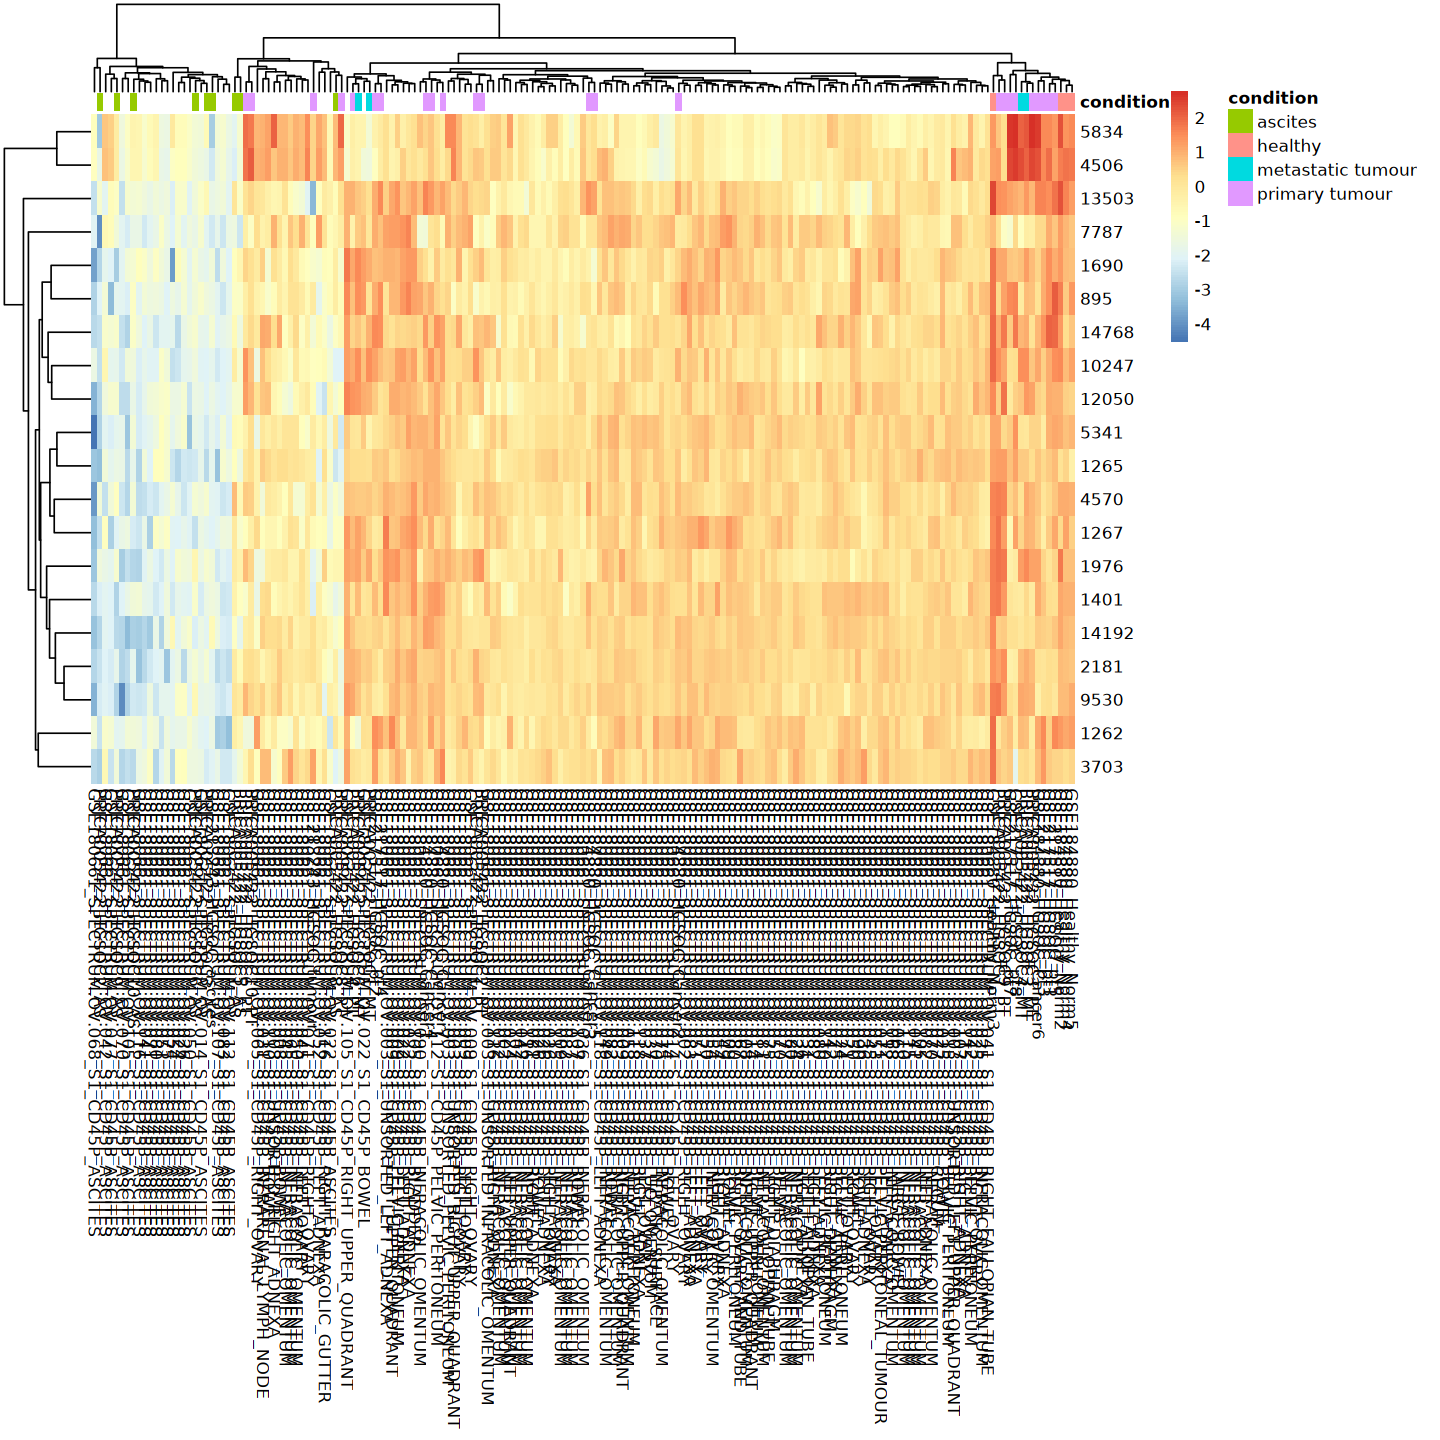

In [ ]:
top20_dc2 <- rownames(
    deg2 %>%
        arrange(adj.P.Val) %>%
        head(20)
)

mat <- v2$E[top20_dc2, ]

mat_scaled <- t(scale(t(mat)))

annotation_col <- data.frame(
    condition =
        metadata_DC2$sample_type_major2
)

rownames(annotation_col) <-
    metadata_DC2$integration_id

pheatmap(
    mat_scaled,
    annotation_col =
        annotation_col,
    cluster_cols = TRUE,
    show_rownames = TRUE
)

options(repr.plot.width=12, repr.plot.height=12)

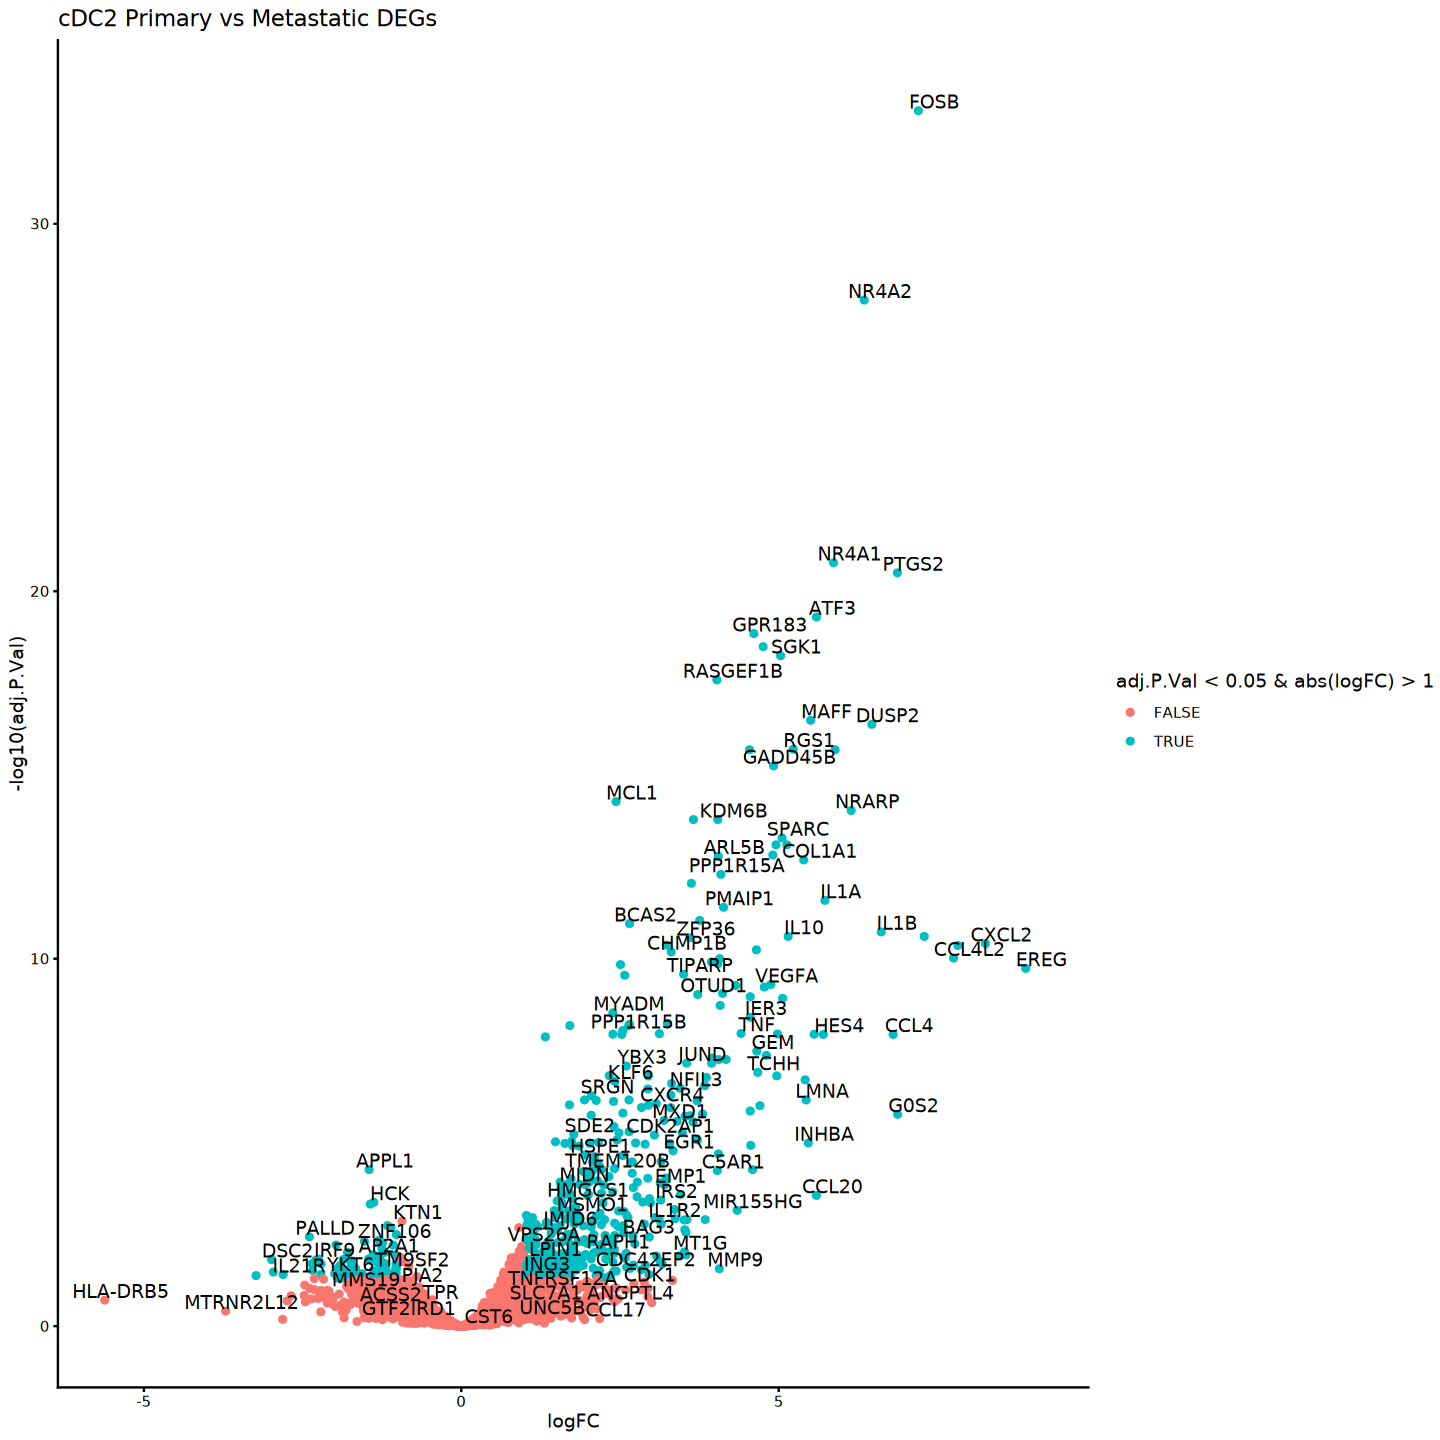

In [ ]:
deg2$gene <- rownames(deg2)

ggplot(deg2,
       aes(logFC, -log10(adj.P.Val), label = X)) +
       geom_point(aes(
        color =
        adj.P.Val < 0.05 &
        abs(logFC) > 1
    )) +
    geom_text(
    label = rownames(deg2$X), 
    nudge_x = 0.25, nudge_y = 0.25, 
    check_overlap = T) +
    theme_classic() +
    labs(title = "cDC2 Primary vs Metastatic DEGs")

### mregDC

In [ ]:
head(deg_mregDC)

,logFC,AveExpr,t,P.Value,adj.P.Val,B
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
12847,1.866435,7.562730,3.914792,0.0004704515,0.1318181,-0.06339134
7866,1.667449,7.615765,3.855402,0.0005538713,0.1318181,-0.20657581
12726,1.658058,9.635209,3.828493,0.0005962689,0.1318181,-0.29053955
6169,2.366362,6.247734,3.831632,0.0005911644,0.1318181,-0.31890395
10912,2.340636,9.453736,3.803787,0.0006379740,0.1318181,-0.36534243
9718,2.258283,5.735162,3.799717,0.0006451131,0.1318181,-0.43870299


In [ ]:
top20_mregdc <- rownames(
    deg_mregDC %>%
        arrange(adj.P.Val) %>%
        head(20)

ERROR: Error in parse(text = input): <text>:5:0: unexpected end of input
3:         arrange(adj.P.Val) %>%
4:         head(20)
  ^


In [ ]:
res3 <- run_limma_deg(
    pseudobulk_mregDC,
    metadata_mregDC
)

deg3 <- res3$deg
v3 <- res3$voom

Setting first column of `counts` as gene annotation.



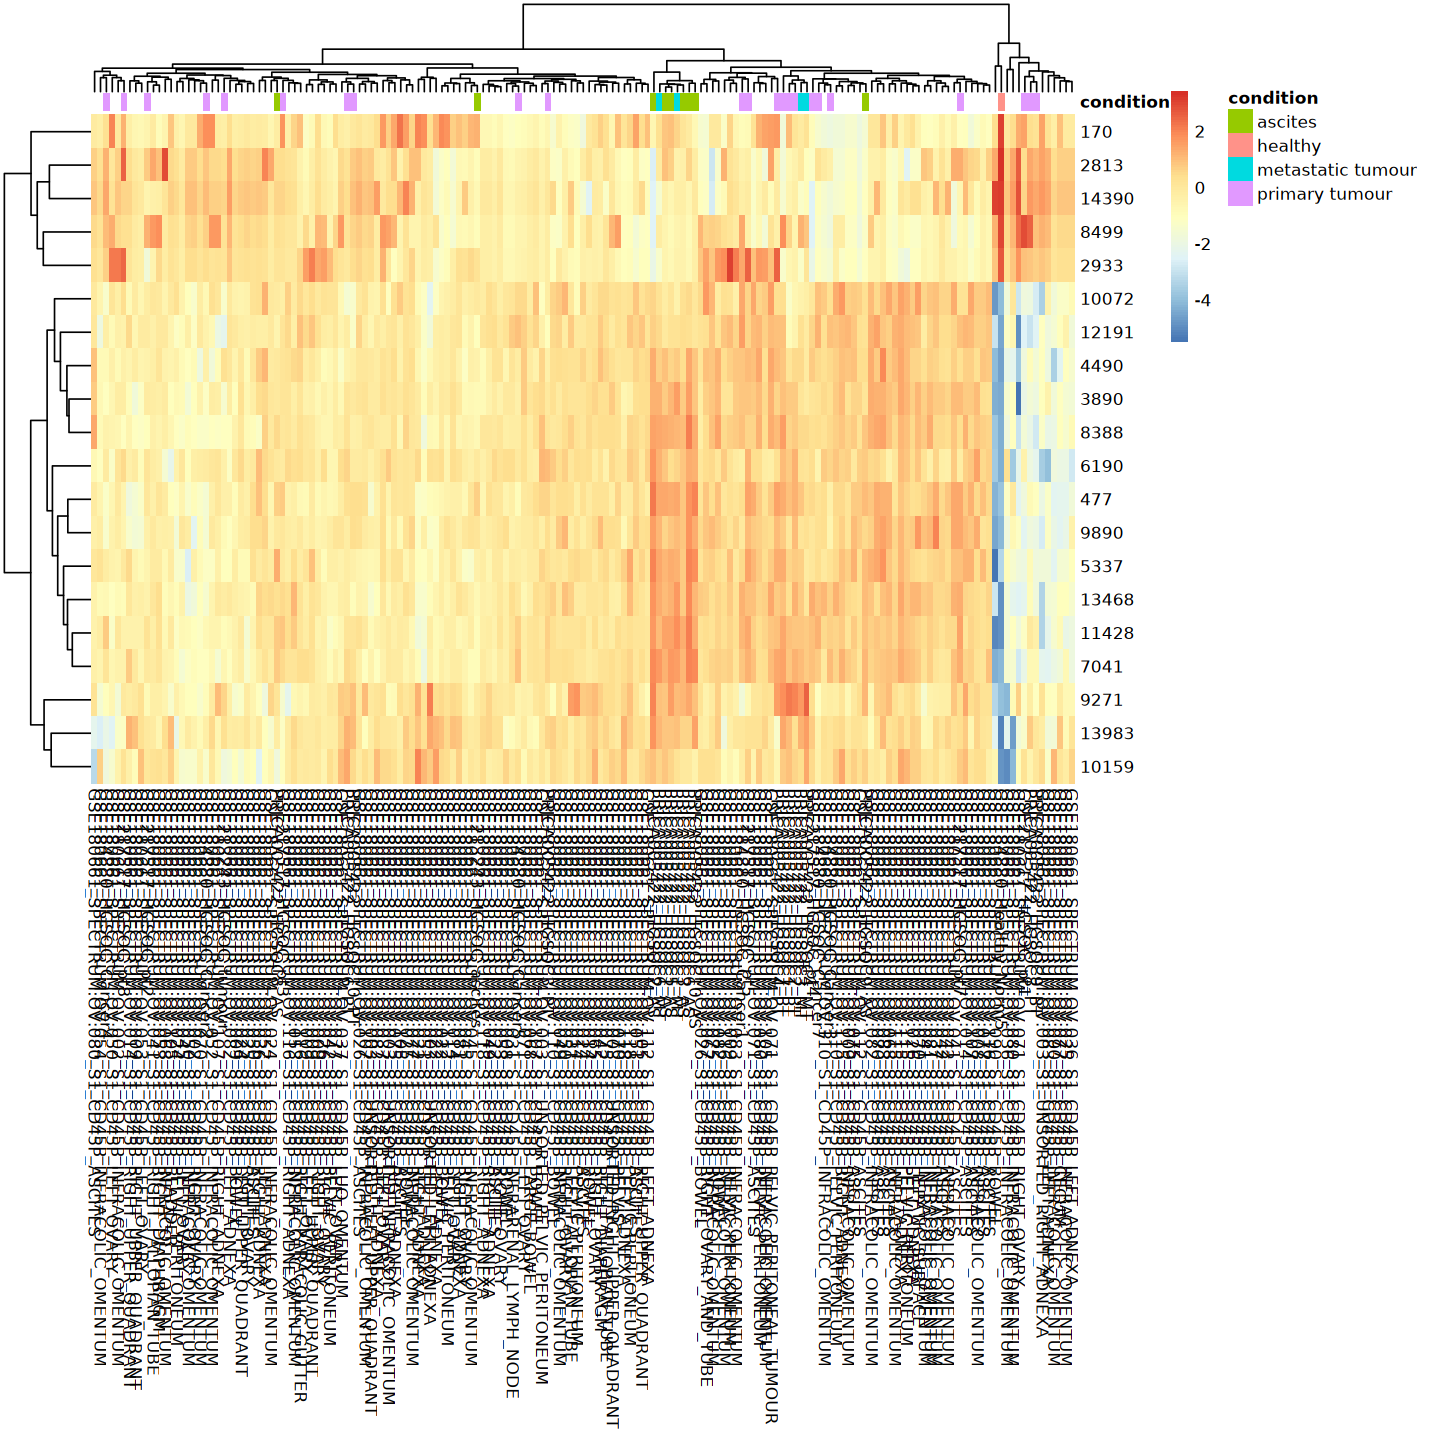

In [ ]:
top20_mregdc <- rownames(
    deg3 %>%
        arrange(adj.P.Val) %>%
        head(20)
)

mat <- v3$E[top20_mregdc, ]

mat_scaled <- t(scale(t(mat)))

annotation_col <- data.frame(
    condition =
        metadata_mregDC$sample_type_major2
)

rownames(annotation_col) <-
    metadata_mregDC$integration_id

pheatmap(
    mat_scaled,
    annotation_col =
        annotation_col,
    cluster_cols = TRUE,
    show_rownames = TRUE
)

options(repr.plot.width=12, repr.plot.height=12)

In [ ]:
head(deg3)

,X,logFC,AveExpr,t,P.Value,adj.P.Val,B
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
11428,RPS15A,-4.296778,11.004871,-4.605759,7.584390e-06,0.01784964,3.339721
13468,RPS15,-3.133533,11.367327,-4.554002,9.473449e-06,0.01784964,3.203261
4490,RPS14,-3.375234,11.509761,-4.481466,1.289866e-05,0.01784964,2.932073
8499,ZC3H12C,4.506224,4.015946,4.404218,1.784712e-05,0.01784964,2.610991
13983,TYROBP,-5.532318,10.088696,-4.388099,1.908846e-05,0.01784964,2.454486
477,RPS8,-3.547576,11.384853,-4.341375,2.317257e-05,0.01784964,2.417878


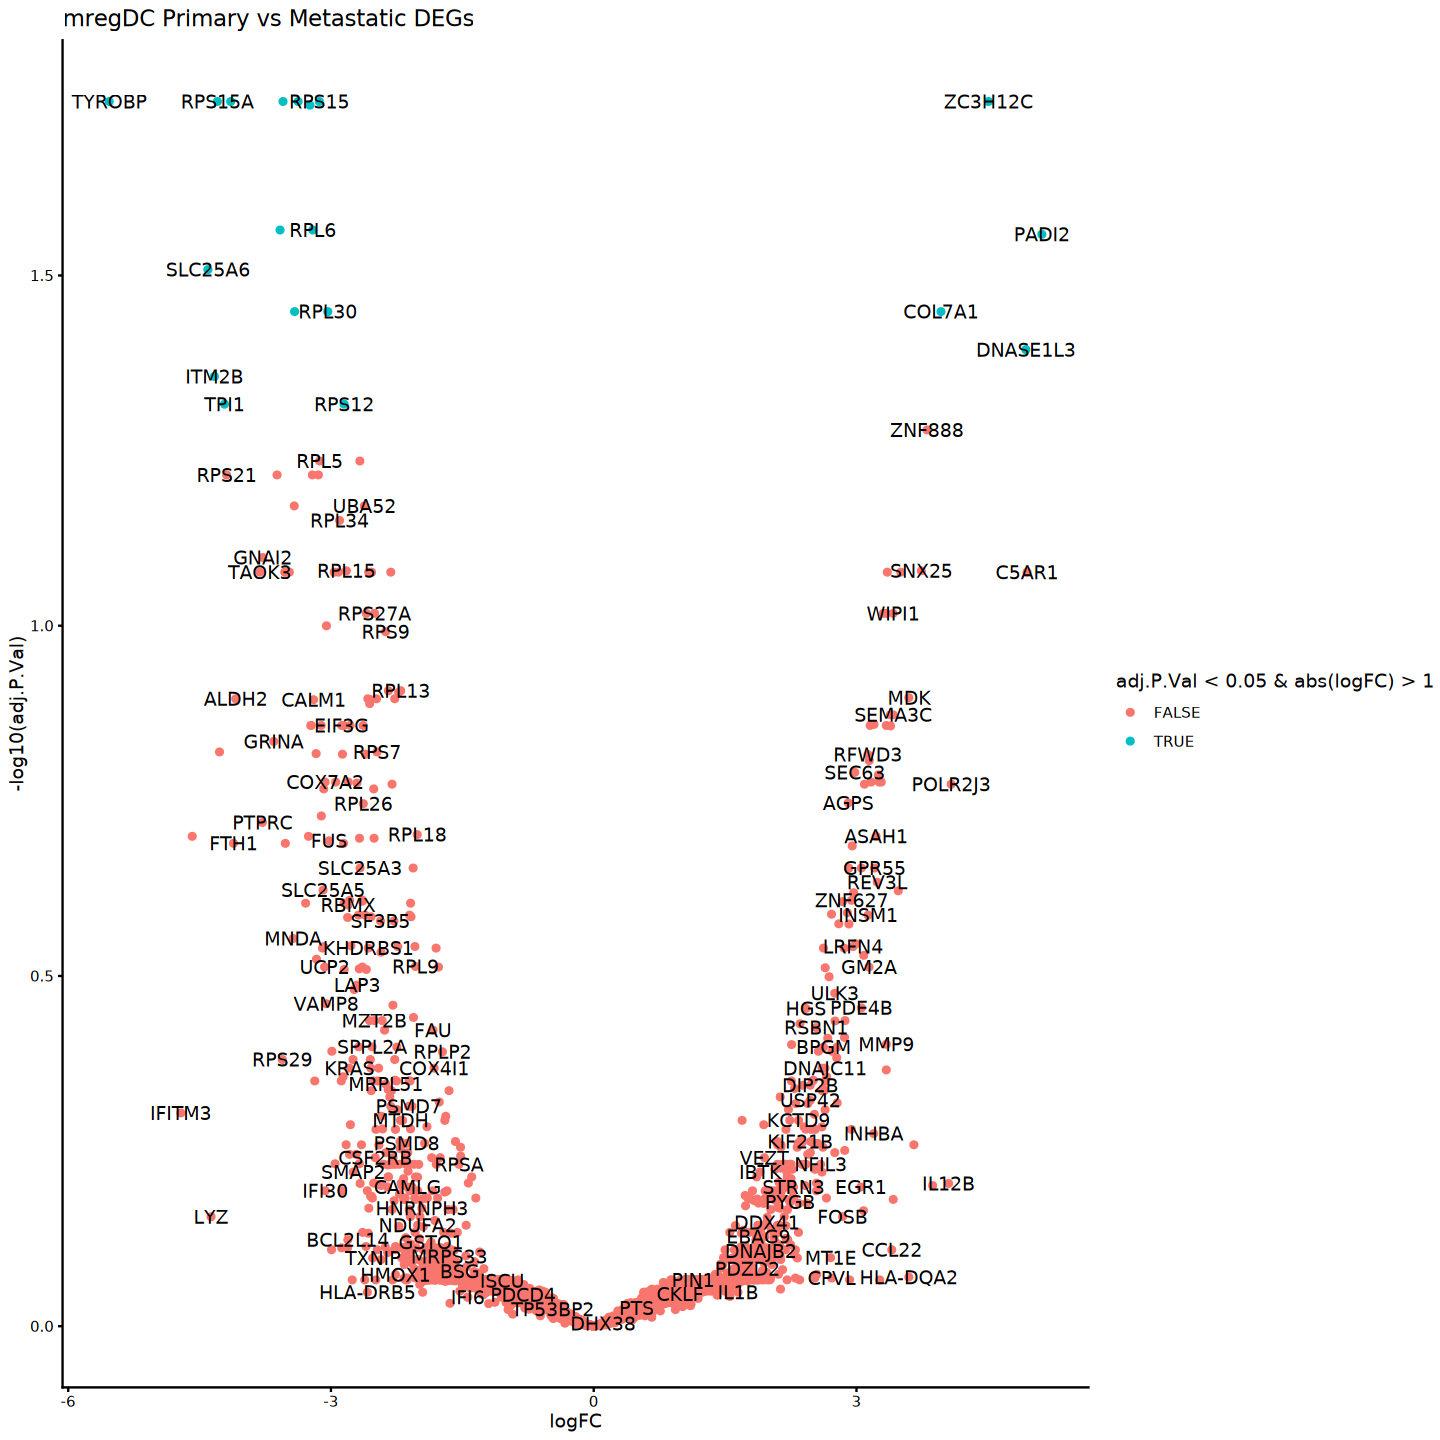

In [ ]:
deg3$gene <- rownames(deg3)

ggplot(deg3,
       aes(logFC, -log10(adj.P.Val), label = X)) +
       geom_point(aes(
        color =
        adj.P.Val < 0.05 &
        abs(logFC) > 1
    )) +
    geom_text(
    label = rownames(deg3$X), 
    #nudge_x = 0.25, nudge_y = 0.25, 
    check_overlap = T) +
    theme_classic() +
    labs(title = "mregDC Primary vs Metastatic DEGs")

### Get Hallmark Pathways

In [ ]:
options(timeout = 300)
library(msigdbr)

In [ ]:
hallmark <- msigdbr(
    species = "Homo sapiens",
    category = "H"
)

ERROR: Error in curl::curl_download(url = release$zip_url, destfile = zip_path, : Timeout was reached [zenodo.org]:
Connection timed out after 10001 milliseconds


IFN pathways

In [ ]:
ifn_alpha <- hallmark %>%
 filter(gs_name ==
 "HALLMARK_INTERFERON_ALPHA_RESPONSE") %>%
 pull(gene_symbol)

ifn_gamma <- hallmark %>%
 filter(gs_name ==
 "HALLMARK_INTERFERON_GAMMA_RESPONSE") %>%
 pull(gene_symbol)

tnf <- hallmark %>%
 filter(gs_name ==
 "HALLMARK_TNFA_SIGNALING_VIA_NFKB") %>%
 pull(gene_symbol)

ERROR: Error: object 'hallmark' not found


KEGG pathways

In [ ]:
kegg <- msigdbr(
    species = "Homo sapiens",
    collection = "C2",
    subcollection = "CP:KEGG"
)

ERROR: Error in curl::curl_download(url = release$zip_url, destfile = zip_path, : Timeout was reached [zenodo.org]:
Connection timed out after 10002 milliseconds


Antigen Presentation

In [ ]:
antigen <- kegg %>%
 filter(gs_name ==
 "KEGG_ANTIGEN_PROCESSING_AND_PRESENTATION") %>%
 pull(gene_symbol)